[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SURIAPRAKASH1/reinforcement-learning/blob/main/notebooks/policy-gradient-methods.ipynb)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Categorical
from torch.utils.data import DataLoader, Dataset

import gymnasium as gym
import math
from gymnasium.wrappers import RecordVideo
import random
import itertools
from queue import deque
import numpy as np
import matplotlib.pyplot as plt

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("current device -->", DEVICE)

current device --> cpu


# Policy Gradient Methods:
- The main goal of an *agent* in reinforcement learning to select an optimal action at each state of environment. Optimal action means, an action that gives maximum reward (usually goal).
## The ways to train an *Agent* to take action:
1. **Learn value-function:** Learn value-functions (specifically action-value function) and act *greedy or $ϵ$-greedy* with respect to learned action-value function.
2. **Learn policy**: Instead of learning value-functions and act greedy or $ϵ$-greedy, learns policy that directly maps state to action.  
## Policy Gradient Methods:
- Policy Graidient Methods learns policy directly using function approximation (linear, neural networks).
- The main advantage of policy gradient methods that it can be applied to continuous *action* space as well and also it has better convergence than learning value-functions.

## REINFORCE: Monte Carlo Policy Gradient control (episodic) for $π_{θ} \approx π_{*}$
- REINFORCE is a policy graident methods that uses monte carlo way to learning $π$ for control problem.
- Because MC uses unbasied version of return $G_{t}$, it usually has high variance.
- Anothor draw back is MC is offline, update only happen at the end of episode.

In [ ]:
# Let's apply reinforce to mountain car problem
env = gym.make("MountainCar-v0")


In [ ]:
# Action space
action_space = env.action_space.n.item()
# State dim: It's ain't state space, most of the state space is continuous
k = state_dim = env.observation_space.shape[0]
order_n = 3

# Hyper Parameters
alpha = 1e-3
weight_decay = 1e-3
Episodes = 200
batch_size = 64
gamma = 0.99

In [ ]:
class Policy(nn.Module):
    "Policy can be any differentiable function, here it's NN"

    def __init__(self, state_dim, hidden_dim, action_space) -> None:
        super().__init__()

        self.l1 = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU()
        )

        self.l2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU()
        )

        # Here we just computing logits only
        self.l3 = nn.Linear(hidden_dim, action_space)

    def forward(self, x) -> torch.Tensor:
        return self.l3(self.l2(self.l1(x)))

# Boundary for postion and velocity: Defined as how in gym lib
min_pos_vel = np.array([-1.2, -0.07], dtype = np.float32)
max_pos_vel = np.array([0.6, 0.07], dtype = np.float32)

# Generate all coefficient vectors (c_i) => range of integers for each component of c_i: {0, 1, ..., n}
all_c_vectors = list(itertools.product(range(0, order_n + 1), repeat=k))

def generate_fourier_features(s: np.ndarray) -> torch.tensor:
        """Constructs the n-order Fourier cosine basis feature vector x(s).

        Args:
            s: state vector (must be 1D).
            order_n: The maximum integer magnitude for the coefficients c_i,j.
        Returns:
            A tensor representing the full feature vector x(s), of size (order_n + 1)^k.
        """
        # 1. Input Validation and Setup
        state_vector = np.asarray(s, dtype=float)

        # 2. Scalling state to within range of [0, 1]
        state_vector = (state_vector - min_pos_vel) / (max_pos_vel - min_pos_vel)

        # 3. Calculate the feature vector x(s)
        feature_list = []

        for c_tuple in all_c_vectors:
            c_i = np.array(c_tuple)

            # Calculate the inner product: s^T * c_i
            # (This combines the scaled state dimensions and the frequencies)
            s_dot_c = np.dot(state_vector, c_i)

            # Calculate the feature: cos(pi * s^T * c_i)
            feature_value = np.cos(np.pi * s_dot_c)
            feature_list.append(feature_value)

        return torch.as_tensor(feature_list, dtype = torch.float32)


# discounted returns helper
def discounted_returns(rewards, gamma):
    R = []
    G = 0.0
    for r in reversed(rewards):
        G = r + gamma * G
        R.append(G)
    return np.array(R[::-1], dtype=np.float32)

# more robust build_batch: sample indices with replacement if len < batch_size
def build_batch(states, actions, rewards, batch_size=32, use_feature=True):
    T = len(rewards)
    if T == 0:
        raise ValueError("Empty episode")
    # compute discounted returns
    G = discounted_returns(rewards, gamma)
    G = torch.as_tensor(G, dtype=torch.float32, device=DEVICE)

    if batch_size > T:
        # sample with replacement, or just use full trajectory
        batch_idx = torch.randint(0, T, size=(batch_size,), device=DEVICE)
    else:
        batch_idx = torch.randint(0, T, size=(batch_size,), device=DEVICE)

    chosen_states = []
    for i in batch_idx.cpu().tolist():   # states list holds feature tensors on DEVICE already
        chosen_states.append(states[i] if not use_feature else generate_fourier_features(states[i].copy()))

    # stack states (ensure on DEVICE)
    if use_feature:
        tensor_states = torch.stack(chosen_states).to(DEVICE)
    else:
        tensor_states = torch.as_tensor(np.asarray(chosen_states), dtype=torch.float32, device=DEVICE)

    chosen_actions = torch.tensor([actions[i].item() if isinstance(actions[i], torch.Tensor) else actions[i]
                                   for i in batch_idx.cpu().tolist()],
                                  dtype=torch.long, device=DEVICE).unsqueeze(1)

    returns = G[batch_idx]   # already on DEVICE

    return tensor_states, chosen_actions, returns


In [ ]:
# Initiating Policy
pi = Policy((order_n + 1)**k, 30, action_space).to(DEVICE)

# Negative Log Liklihood loss: Cross Entropy == Log softmax followed by NLL
# loss_fn = nn.CrossEntropyLoss()
def compute_loss(inputs, targets, weights):
    log_p = F.log_softmax(pi(inputs), dim = 1).gather(dim = 1, index = targets)
    return -(log_p.flatten() * weights).mean()

# Optimizer Wadam
policy_optimizer = optim.AdamW(pi.parameters(), lr = alpha, weight_decay= weight_decay)

In [ ]:
# One run means One episode: return for episode is total return on that episode
run_return = []
losses = []
# Optimization Loop
for ep in range(Episodes):

    # Always start with new environment
    state, _ = env.reset()
    states = []
    actions = []
    rewards = []

    # Trajectory followed by pi
    while True:
        # On policy gradient method there no greedy or epsilon greedy everything is learnable
        with torch.no_grad():
            action = pi(generate_fourier_features(state)).softmax(dim = 0).multinomial(1)
        next_state, reward, terminated, truncated, _ = env.step(action.item())

        states.append(state)
        actions.append(action)
        rewards.append(reward)

        if terminated or truncated:
            break
        state = next_state

    # Sample Batch: Train only single batch per episode to prevent overfitting
    States, Actions, Returns = build_batch(states, actions, rewards, batch_size= batch_size, use_feature= True)

    policy_optimizer.zero_grad()
    # Forward pass & Compute loss
    loss = compute_loss(States, Actions, Returns)
    # Backward Pass: Compute Gradients
    loss.backward()
    # Gradient clipping
    nn.utils.clip_grad_norm_(pi.parameters(), 0.3)
    # Update parameters
    policy_optimizer.step()

    # We shouldn't consider loss only have to consider return
    losses.append(loss.item())
    run_return.append(sum(rewards))

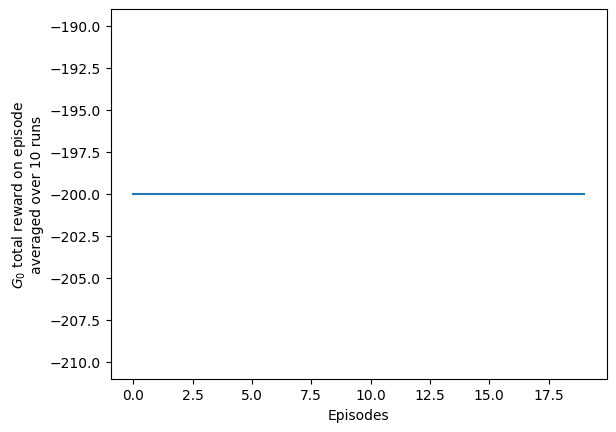

In [ ]:
# Average over runs
runs = 10
plt.plot(torch.as_tensor(run_return).view(-1, runs).mean(dim = 1))
plt.xlabel(f"Episodes")
plt.ylabel(f"$G_{0}$ total reward on episode \naveraged over {runs} runs")
plt.show()

### Evaluate

In [ ]:
rewards = 0.0
state, _ = env.reset()
while True:
    # Ethier train or inference we have take sample like in LLM
    with torch.no_grad():
        action = pi(torch.as_tensor(state, device = DEVICE)).softmax(dim = 0).multinomial(1).item()
    state, reward, terminated, truncated, _ = env.step(action)
    rewards += reward

    if terminated or truncated:
        break

In [ ]:
# We want less negative rewards and terminated ==> that means achive goal with less step step
rewards, terminated, truncated

(-200.0, False, True)

## Actor-Critic Methods:
- The problem with navie *REINFORCE* methods is that on it's core it just a *Monte Carlo* method so it's uses *un-baised return* on it's learning. Unbaised return has high variance.
- *Actor-Critic* methods learns *policy* and *critic*. Think of that policy an an actor who take every actions, critic the one who evaluate that taken action by policy.
- Also actor-critic methods uses bootstrapping (can be $TD(0), n-step, TD(\lambda)$), it's baised but low variance and *online learning*.

In [ ]:
# Mountain Car problem
env = gym.make("MountainCar-v0")

In [ ]:
# Action space
action_space = env.action_space.n.item()
# State dim: It's ain't state space, most of the state space is continuous
k = state_dim = env.observation_space.shape[0]

# Hyper Parameters
order_n = 3                           # If we want to uses feature
max_actor_alpha = 6e-3                # Step-size for policy - actor
min_actor_alpha = 5e-5
max_critic_alpha = 2.5e-2             # Step-size for value-function - critic
min_critic_alpha = 1e-4
warmup_steps = 4000                   # Warmup
keep_stay =  9000                     # Keep stay max lr
actor_weight_decay = 1e-1
critic_weight_decay = 1e-1
Episodes = 200
batch_size = 128
GAMMA = 0.99
hidden_dim_actor = 200
hidden_dim_critic = 150
max_experience_replay_size = 10000
tau = 0.005                       # Soft-update for target network

In [ ]:
class Policy(nn.Module):
    "Policy can be any differentiable function, here it's NN"

    def __init__(self, state_dim, hidden_dim, action_space) -> None:
        super().__init__()

        self.l1 = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU()
        )

        self.l2 = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU()
        )

        # Here we just computing logits only
        self.l3 = nn.Linear(hidden_dim, action_space)

    def total_parameters(self)-> int:
        total = 0.0
        for params in self.parameters():
            total += params.nelement()
        return total

    def forward(self, x) -> torch.Tensor:
        return self.l3(self.l2(self.l1(x)))

class Critic(nn.Module):
    "Critic aka value-function to evaluate actor aka policy"

    def __init__(self, state_dim, hidden_dim) -> None:
        super().__init__()

        self.critic = nn.Sequential(
            nn.Linear(state_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.RMSNorm(hidden_dim, eps=1e-8),
            nn.GELU(),
            nn.Linear(hidden_dim, 1)
        )

    def total_parameters(self)-> int:
        total = 0.0
        for params in self.parameters():
            total += params.nelement()
        return total

    def forward(self, x) -> torch.Tensor:
        return self.critic(x)

def soft_update(critic_target_net: nn.Module, critic_learning_net: nn.Module, tau: float):
    "Soft update to target network parameters. Gradually changing instead hard."
    for target_params, learning_params in zip(critic_target_net.parameters(), critic_learning_net.parameters()):
        target_params.data.copy_((1 - tau) * target_params.data + tau * learning_params.data)

class ExperienceReplay(Dataset):

    def __init__(self, max_experience_replay_size: int, k: int, order_n: int):
        self.memory = deque(maxlen = max_experience_replay_size)
        # ---------------------
        # Fearture Construction
        # ---------------------

        # Boundary for postion and velocity: Defined as how in gym lib
        self.min_pos_vel = np.array([-1.2, -0.07], dtype = np.float32)
        self.max_pos_vel = np.array([0.6, 0.07], dtype = np.float32)

        # Generate all coefficient vectors (c_i) => range of integers for each component of c_i: {0, 1, ..., n}
        self.all_c_vectors = list(itertools.product(range(0, order_n + 1), repeat=k))

    def __len__(self):
        return len(self.memory)

    def update(self, state, action, reward, next_state, done):
        self.memory.append((state, action, reward, next_state, done))

    def generate_fourier_features(self, s: np.ndarray) -> torch.tensor:
        """Constructs the n-order Fourier cosine basis feature vector x(s).

        Args:
            s: state vector (must be 1D).
            order_n: The maximum integer magnitude for the coefficients c_i,j.
        Returns:
            A tensor representing the full feature vector x(s), of size (order_n + 1)^k.
        """
        # 1. Input Validation and Setup
        state_vector = np.asarray(s, dtype=float)

        # 2. Scalling state to within range of [0, 1]
        state_vector = (state_vector - self.min_pos_vel) / (self.max_pos_vel - self.min_pos_vel)

        # 3. Calculate the feature vector x(s)
        feature_list = []

        for c_tuple in self.all_c_vectors:
            c_i = np.array(c_tuple)

            # Calculate the inner product: s^T * c_i
            # (This combines the scaled state dimensions and the frequencies)
            s_dot_c = np.dot(state_vector, c_i)

            # Calculate the feature: cos(pi * s^T * c_i)
            feature_value = np.cos(np.pi * s_dot_c)
            feature_list.append(feature_value)

        return torch.as_tensor(feature_list, dtype = torch.float32)

    def __getitem__(self, idx):
        state, action, reward, next_state, done = self.memory[idx]
        state_fea = self.generate_fourier_features(state)
        next_state_fea = self.generate_fourier_features(next_state)
        return (state_fea,
                torch.as_tensor(action, dtype = torch.long),
                torch.as_tensor(reward, dtype = torch.float32),
                next_state_fea,
                torch.tensor(done, dtype = torch.bool))

class CosineWarmupScheduler(optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, warmup_steps, max_lr, min_lr, total_steps, keep_stay, last_epoch=-1):
        self.warmup_steps = warmup_steps    # Number of steps to warmup
        self.max_lr = max_lr                # warmup approches max lr
        self.min_lr = min_lr                # decrese to min lr
        self.total_steps = total_steps      # Total steps/epoch
        self.keep_stay = keep_stay
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        if self.last_epoch < self.warmup_steps:
            # Linear warmup
            lr = self.max_lr * (self.last_epoch / self.warmup_steps)
        elif self.last_epoch < self.keep_stay:
            lr = self.max_lr
        else:
            # Cosine annealing
            progress = (self.last_epoch - self.warmup_steps) / (self.total_steps - self.warmup_steps)
            lr = self.min_lr + 0.5 * (self.max_lr - self.min_lr) * (1 + math.cos(math.pi * progress))
        return [lr for _ in self.optimizer.param_groups]

class Trainer:

    def __init__(self,
                 max_actor_alpha: float = 0.001,
                 min_actor_alpha: float = 0.001,
                 max_critic_alpha: float = 0.001,
                 min_critic_alpha: float = 0.001,
                 actor_weight_decay: float = 0.1,
                 critic_weight_decay: float = 0.1,
                 batch_size: int = 32,
                 warmup_steps: int = 20,
                 keep_stay: int = 20,
                 total_steps: int = 100):

        self.max_actor_alpha = max_actor_alpha
        self.min_actor_alpha = min_actor_alpha
        self.max_critic_alpha = max_critic_alpha
        self.min_critic_alpha = min_critic_alpha
        self.warmup_steps = warmup_steps
        self.keep_stay = keep_stay
        self.total_steps = total_steps
        self.actor_weight_decay = actor_weight_decay
        self.critic_weight_decay = critic_weight_decay
        self.batch_size = batch_size
        self.actor_optimizer = None
        self.actor_lr_scheduler = None
        self.critic_optimizer = None
        self.critic_lr_scheduler = None
        self.dataloader = None

    def train(self, actor: nn.Module, critic: nn.Module, critic_target: nn.Module,
            dataset, init_actor_alpha, init_critic_alpha, batches:int = 1, gamma = 1.0):
        "When experience replay is got enought sample we are doing Supervised Learning."

        if len(dataset) < batch_size:
            return

        if self.dataloader is None:
            self.dataloader = DataLoader(dataset, self.batch_size, shuffle= True,
                                                pin_memory= True if DEVICE == 'cuda' else False)

        if not (self.actor_optimizer and self.critic_optimizer):
            # Initiating optimizers
            self.actor_optimizer = optim.AdamW(actor.parameters(),
                                              lr = init_actor_alpha, weight_decay= self.actor_weight_decay)
            self.critic_optimizer = optim.AdamW(critic.parameters(),
                                              lr = init_critic_alpha, weight_decay= self.critic_weight_decay)

            # Initiating lr scheduler
            self.actor_lr_scheduler = CosineWarmupScheduler(self.actor_optimizer, self.warmup_steps,
                                                            self.max_actor_alpha, self.min_actor_alpha,
                                                            self.total_steps,self.keep_stay)
            self.critic_lr_scheduler = CosineWarmupScheduler(self.critic_optimizer, self.warmup_steps,
                                                            self.max_critic_alpha, self.min_critic_alpha,
                                                            self.total_steps, self.keep_stay)
        losses = 0.0
        # Usually single batch is enough. If we multiple batch then agen will overfit
        for batch, (states, actions, rewards, next_states, dones) in enumerate(self.dataloader):
            if DEVICE == 'cuda':
                states, next_states = states.to(DEVICE), next_states.to(DEVICE)
                rewards, dones = rewards.to(DEVICE), dones.to(DEVICE)
                actions = actions.to(DEVICE)

            # ---------------------------------------------------------
            # Compute TD error = R + gamma * v_hat(S', w) - v_hat(S, w)
            # ------------------------------------------------- -------
            self.critic_optimizer.zero_grad()
            with torch.no_grad():
                TD_target = rewards + gamma * critic_target(next_states).detach().flatten() * ~dones
            TD_error = F.smooth_l1_loss(critic(states).flatten(), TD_target)
            # Backward pass: compute gradients
            TD_error.backward()
            # Update Parameters-w
            nn.utils.clip_grad_norm_(critic.parameters(), 0.3)
            self.critic_optimizer.step()
            self.critic_lr_scheduler.step()

            # ----------------------------------------------------
            # Use TD error to tell actor "is he did well or not ?"
            # ----------------------------------------------------
            self.actor_optimizer.zero_grad()
            # Forward pass: logits for action-space
            logits = actor(states)
            # Compute loss: NLL
            pi_loss = F.cross_entropy(logits, actions)
            # Backward pass: compute gradients in the direction of TD_error
            (pi_loss * (TD_error).detach()).backward()
            # Update Parameters-theta
            nn.utils.clip_grad_norm_(actor.parameters(), 0.3)
            self.actor_optimizer.step()
            self.actor_lr_scheduler.step()

            losses += pi_loss.item()
            if batch == batches - 1:
                break
        return losses


In [ ]:
# Initiate actor and critic
pi = Policy((order_n + 1)**k, hidden_dim_actor, action_space).to(DEVICE)
critic = Critic((order_n + 1)**k, hidden_dim_critic).to(DEVICE)
# Critic target
critic_target = Critic((order_n + 1)**k, hidden_dim_critic).to(DEVICE)
critic_target.load_state_dict(critic.state_dict())

# Total Parameters
print(f"Actor params: {pi.total_parameters()}\nCritic params: {critic.total_parameters()}")

Actor params: 44603.0
Critic params: 25651.0


In [ ]:
# Initiating Memory
dataset = ExperienceReplay(max_experience_replay_size, k, order_n)
trainer = Trainer(
    max_actor_alpha= max_actor_alpha,
    min_actor_alpha= min_actor_alpha,
    max_critic_alpha= max_critic_alpha,
    min_critic_alpha= min_critic_alpha,
    actor_weight_decay= actor_weight_decay,
    critic_weight_decay= critic_weight_decay,
    batch_size= batch_size,
    warmup_steps= warmup_steps,
    keep_stay= keep_stay,
    total_steps= (Episodes * 200)
)

In [ ]:
losses = []       # Every time-step
run_returns = []   # One-run return == total rewards in single episode

for ep in range(Episodes):
    pi_losses = []

    # Always begin with new env
    state, _ = env.reset()
    I, run_return = 1.0, 0.0

    while True:
        # Take action A and observer S', R
        with torch.no_grad():
            action = Categorical(logits= pi(dataset.generate_fourier_features(state).to(DEVICE))).sample().item()
        next_state, reward, terminated, truncated, _ = env.step(action)
        run_return += reward

        # Store experience
        dataset.update(state, action, reward, next_state, terminated)

        # Train on mini-batch of experience in supervised way
        loss = trainer.train(pi, critic, critic_target, dataset, max_actor_alpha, max_critic_alpha, gamma= I)

        # Update (soft-update) Target network at every time step
        soft_update(critic_target, critic, tau)

        if loss:
            pi_losses.append(loss)
        if terminated or truncated:
            break
        state = next_state
        I *= GAMMA

    if ep % 10 == 0 and len(pi_losses) >= 1:
        print(f"Episode {ep}: pi loss = {sum(pi_losses)/len(pi_losses)}")

    losses.extend(pi_losses)
    run_returns.append(run_return)

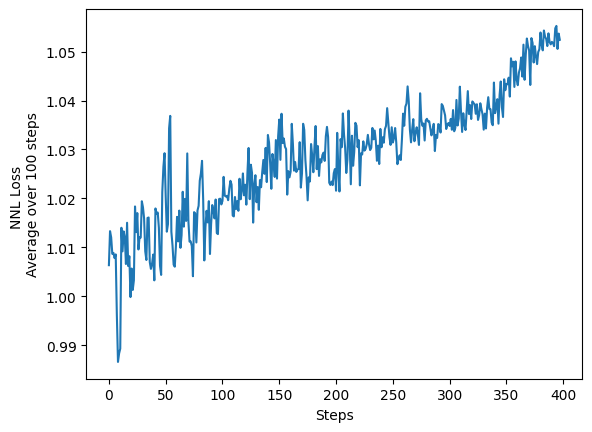

In [ ]:
# Visualizing loss (doesn't matter for policy gradient methods)
average_over = 100
plt.plot(torch.as_tensor(losses[:-73]).view(-1, average_over).mean(1))
plt.xlabel(f"Steps")
plt.ylabel(f"NNL Loss \nAverage over {average_over} steps")
plt.show()

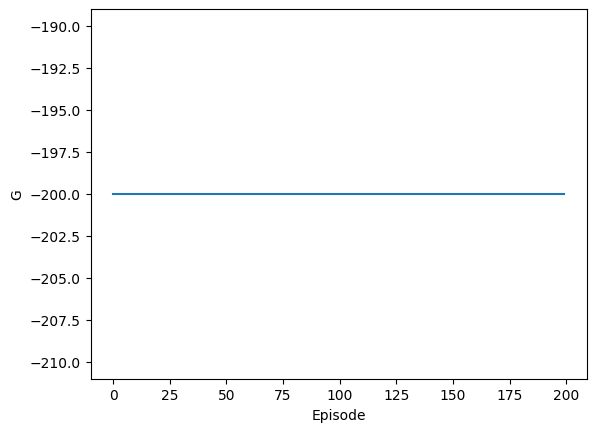

In [ ]:
# Visualizing returns (have to be less negative)
plt.plot(run_returns)
plt.xlabel("Episode")
plt.ylabel("G")
plt.show()

### Evaluate:

In [ ]:
import glob
from IPython.display import display, Video

In [ ]:
# Goal of the agent terminated true with lower negative reward (that's mean agent takes less timestep)

env = gym.make("MountainCar-v0", render_mode = "rgb_array")
env = RecordVideo(env, video_folder= "/content/videos", episode_trigger=lambda x: True)
state, _ = env.reset()

pi.eval()
rewards = 0.0
while True:
    # Ethier train or inference we have take draw action as sample like how in LLM
    with torch.no_grad():
        action = Categorical(logits = pi(dataset.generate_fourier_features(state).to(DEVICE))).sample().item()
    state, reward, terminated, truncated, _ = env.step(action)
    rewards += reward

    if terminated or truncated:
        break
env.close()

# find the mp4 in /content/videos and display it (first video)
videos = sorted(glob.glob("/content/videos/*.mp4"))
print("Saved videos:", videos)
print(f"Time step takes for agent to complete: {-rewards}")

/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:434: UserWarning: WARN: Unable to save last video! Did you call close()?
  logger.warn("Unable to save last video! Did you call close()?")
/usr/local/lib/python3.12/dist-packages/gymnasium/wrappers/rendering.py:293: UserWarning: WARN: Overwriting existing videos at /content/videos folder (try specifying a different `video_folder` for the `RecordVideo` wrapper if this is not desired)
  logger.warn(


Saved videos: ['/content/videos/rl-video-episode-0.mp4', '/content/videos/rl-video-episode-1.mp4', '/content/videos/rl-video-episode-10.mp4', '/content/videos/rl-video-episode-100.mp4', '/content/videos/rl-video-episode-101.mp4', '/content/videos/rl-video-episode-102.mp4', '/content/videos/rl-video-episode-103.mp4', '/content/videos/rl-video-episode-104.mp4', '/content/videos/rl-video-episode-105.mp4', '/content/videos/rl-video-episode-106.mp4', '/content/videos/rl-video-episode-107.mp4', '/content/videos/rl-video-episode-108.mp4', '/content/videos/rl-video-episode-109.mp4', '/content/videos/rl-video-episode-11.mp4', '/content/videos/rl-video-episode-110.mp4', '/content/videos/rl-video-episode-111.mp4', '/content/videos/rl-video-episode-112.mp4', '/content/videos/rl-video-episode-113.mp4', '/content/videos/rl-video-episode-114.mp4', '/content/videos/rl-video-episode-115.mp4', '/content/videos/rl-video-episode-116.mp4', '/content/videos/rl-video-episode-117.mp4', '/content/videos/rl-vid

In [ ]:
display(Video(videos[-1], embed=True, width=640, height=480))

## Let's have fun torch rl

In [ ]:
%%capture
!uv pip install torchrl tensordict

In [ ]:
import torch
import torch.nn as nn

import torchrl
from torchrl.envs import GymEnv
from torchrl.modules import Actor, MLP
from tensordict.nn import TensorDictModule

In [ ]:
# Mountain Car env
env = GymEnv("MountainCar-v0")

In [ ]:
module = nn.LazyLinear(out_features= env.action_spec.shape[-1])
policy = TensorDictModule(
    module,
    in_keys = ['observation'],
    out_keys = ['action'],
)
# rollout will give us experience taken by policy on real world
rollout = env.rollout(max_steps=10, policy=policy)

In [ ]:
# torchrl gives default policy backbone like MLP, CNN
mlp_backbone = MLP(
    out_features = env.action_spec.shape[-1],
    num_cells = [32, 64],
    activation_class = nn.ReLU,
    norm_class = nn.RMSNorm,
    norm_kwargs = [{"normalized_shape": 32}, {"normalized_shape": 64}],
)

In [ ]:
# torchrl Actor module has build in support to do what TensorModuleDict did
det_policy = Actor(mlp_backbone)

In [ ]:
batch_rollout = env.rollout(max_steps=15, policy=det_policy)

Let' consider stochstic policy that gives distribution over action space.
- Discrite action space (propability for each action and sample from that)
- Continuous action space (Intervel and sample from that interval so policy has to output mean-μ and std-$σ$)

In [ ]:
from torchrl.modules import ProbabilisticActor
from tensordict.nn.distributions import NormalParamExtractor
from torch.distributions import Normal, Categorical

In [ ]:
# env = GymEnv("Pendulum-v1")

In [ ]:
backbone = MLP(
    out_features = env.action_spec.shape[-1],
    num_cells = [16, 32],
    activation_class = nn.Tanh,
    norm_class = nn.RMSNorm,
    norm_kwargs = [{"normalized_shape": 16}, {"normalized_shape": 32}],
)
# Extractor: Will split output of the backbone to get mean and std
# extractor = NormalParamExtractor()
# module = nn.Sequential(backbone, extractor)
td_module = TensorDictModule(backbone, in_keys="observation", out_keys="logits")
prob_policy = ProbabilisticActor(
    td_module,
    in_keys= ["logits"], #["loc", "scale"],
    out_keys=["action"],
    distribution_class= Categorical, #Normal,
    return_log_prob= True
)

rollout = env.rollout(max_steps=10, policy=prob_policy)

In [ ]:
rollout['observation'], rollout['action'], rollout['action_log_prob']